<a href="https://colab.research.google.com/github/Alisa-Zakharova/data_analysis_portfolio/blob/main/olist.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

path = kagglehub.dataset_download("olistbr/brazilian-ecommerce")
print("path =", path)
print("files:", sorted(f for f in os.listdir(path) if f.endswith(".csv")))

Using Colab cache for faster access to the 'brazilian-ecommerce' dataset.
path = /kaggle/input/brazilian-ecommerce
files: ['olist_customers_dataset.csv', 'olist_geolocation_dataset.csv', 'olist_order_items_dataset.csv', 'olist_order_payments_dataset.csv', 'olist_order_reviews_dataset.csv', 'olist_orders_dataset.csv', 'olist_products_dataset.csv', 'olist_sellers_dataset.csv', 'product_category_name_translation.csv']


In [ ]:
orders    = pd.read_csv(os.path.join(path, "olist_orders_dataset.csv"))
items     = pd.read_csv(os.path.join(path, "olist_order_items_dataset.csv"))
customers = pd.read_csv(os.path.join(path, "olist_customers_dataset.csv"))
reviews   = pd.read_csv(os.path.join(path, "olist_order_reviews_dataset.csv"))
products  = pd.read_csv(os.path.join(path, "olist_products_dataset.csv"))
sellers   = pd.read_csv(os.path.join(path, "olist_sellers_dataset.csv"))

tables = {
    "orders": orders,
    "items": items,
    "customers": customers,
    "reviews": reviews,
    "products": products,
    "sellers": sellers,
}

for name, df in tables.items():
    print(f"{name}: shape={df.shape}")

orders: shape=(99441, 8)
items: shape=(112650, 7)
customers: shape=(99441, 5)
reviews: shape=(99224, 7)
products: shape=(32951, 9)
sellers: shape=(3095, 4)


In [ ]:
summary = []
for name, df in tables.items():
    summary.append({
        "table": name,
        "rows": len(df),
        "cols": df.shape[1],
        "missing_cells": int(df.isna().sum().sum()),
        "dup_rows": int(df.duplicated().sum()),
    })
print(pd.DataFrame(summary))

       table    rows  cols  missing_cells  dup_rows
0     orders   99441     8           4908         0
1      items  112650     7              0         0
2  customers   99441     5              0         0
3    reviews   99224     7         145903         0
4   products   32951     9           2448         0
5    sellers    3095     4              0         0


In [ ]:
date_cols = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]
orders[date_cols] = orders[date_cols].apply(pd.to_datetime, errors="coerce")
orders[date_cols].dtypes

,0
order_purchase_timestamp,datetime64[ns]
order_approved_at,datetime64[ns]
order_delivered_carrier_date,datetime64[ns]
order_delivered_customer_date,datetime64[ns]
order_estimated_delivery_date,datetime64[ns]


In [ ]:
print("=== order_status vs missing delivered date ===")
check = (orders.assign(no_delivery=orders["order_delivered_customer_date"].isna())
               .groupby("order_status")["no_delivery"]
               .agg(missing="sum", total="count"))
check["share_missing"] = (check["missing"] / check["total"]).round(3)
print(check.sort_values("total", ascending=False))

=== order_status vs missing delivered date ===
              missing  total  share_missing
order_status                               
delivered           8  96478           0.00
shipped          1107   1107           1.00
canceled          619    625           0.99
unavailable       609    609           1.00
invoiced          314    314           1.00
processing        301    301           1.00
created             5      5           1.00
approved            2      2           1.00


In [ ]:
print("orders:", len(orders))
print("unique customer_id:", orders["customer_id"].nunique())
print("unique customer_unique_id:", customers["customer_unique_id"].nunique())

orders: 99441
unique customer_id: 99441
unique customer_unique_id: 96096


In [ ]:
print("duplicated order_id in reviews:", reviews["order_id"].duplicated().sum())
print("review coverage:", round(orders["order_id"].isin(reviews["order_id"]).mean(), 3))

duplicated order_id in reviews: 551
review coverage: 0.992


In [ ]:
orders["delivery_days"] = (
    orders["order_delivered_customer_date"] - orders["order_purchase_timestamp"]
).dt.days

orders["delay_days"] = (
    orders["order_delivered_customer_date"] - orders["order_estimated_delivery_date"]
).dt.days

orders["is_delivered"] = orders["order_delivered_customer_date"].notna()
orders["is_late"] = (orders["delay_days"] > 0).astype("Int64")

print("=== delivery_days ===")
print(orders["delivery_days"].describe(percentiles=[.01, .5, .9, .99]).round(1))
print("\n=== delay_days ===")
print(orders["delay_days"].describe(percentiles=[.01, .5, .9, .99]).round(1))

=== delivery_days ===
count    96476.0
mean        12.1
std          9.6
min          0.0
1%           1.0
50%         10.0
90%         23.0
99%         46.0
max        209.0
Name: delivery_days, dtype: float64

=== delay_days ===
count    96476.0
mean       -11.9
std         10.2
min       -147.0
1%         -36.0
50%        -12.0
90%         -2.0
99%         18.0
max        188.0
Name: delay_days, dtype: float64


In [ ]:
delivered = orders[orders["is_delivered"] & orders["delay_days"].notna()].copy()

late_rate = delivered["is_late"].mean()
print(f"Delivered orders: {len(delivered):,}")
print(f"Late Delivery Rate: {late_rate:.2%}")

Delivered orders: 96,476
Late Delivery Rate: 6.77%


In [ ]:
# агрегируем отзывы до 1 строки на заказ (берём последний по дате)
reviews_agg = (reviews.sort_values("review_creation_date")
                      .groupby("order_id")
                      .agg(review_score=("review_score", "last"))
                      .reset_index())

df = orders.merge(reviews_agg, on="order_id", how="left")

def delay_bucket(d):
    if pd.isna(d): return None
    if d <= 0:  return "0. On time/early"
    if d <= 3:  return "1. 1-3 days"
    if d <= 7:  return "2. 4-7 days"
    if d <= 14: return "3. 8-14 days"
    return "4. 15+ days"

df["delay_bucket"] = df["delay_days"].apply(delay_bucket)

res = (df.dropna(subset=["delay_bucket", "review_score"])
         .groupby("delay_bucket")
         .agg(avg_score=("review_score", "mean"),
              low_review_rate=("review_score", lambda s: (s <= 2).mean()),
              n=("review_score", "size"))
         .round(3))
print(res)

                  avg_score  low_review_rate      n
delay_bucket                                       
0. On time/early      4.290            0.093  89448
1. 1-3 days           3.291            0.321   1852
2. 4-7 days           2.105            0.676   1748
3. 8-14 days          1.672            0.801   1447
4. 15+ days           1.723            0.784   1335


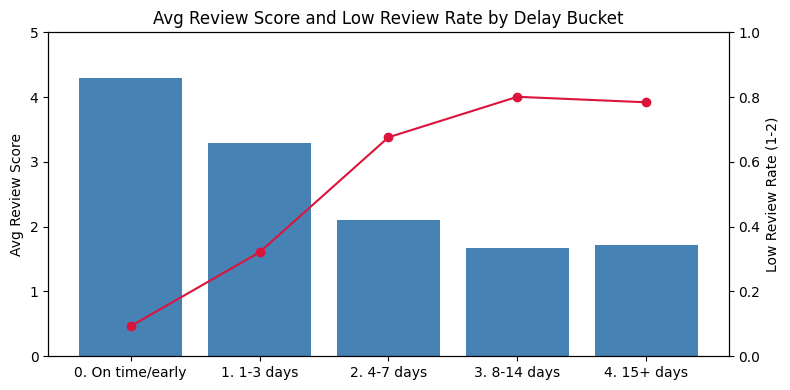

In [ ]:
fig, ax1 = plt.subplots(figsize=(8, 4))

ax1.bar(res.index, res["avg_score"], color="steelblue")
ax1.set_ylabel("Avg Review Score")
ax1.set_ylim(0, 5)
ax1.set_title("Avg Review Score and Low Review Rate by Delay Bucket")

ax2 = ax1.twinx()
ax2.plot(res.index, res["low_review_rate"], color="crimson", marker="o")
ax2.set_ylabel("Low Review Rate (1-2)")
ax2.set_ylim(0, 1)

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [ ]:
# GMV на уровне заказа: SUM(price) по позициям
items_agg = (items.groupby("order_id")
                  .agg(gmv=("price", "sum"),
                       freight=("freight_value", "sum"),
                       n_items=("order_item_id", "count"))
                  .reset_index())

fact = orders.merge(items_agg, on="order_id", how="left")

delivered_fact = fact[fact["is_delivered"]].copy()

gmv_total   = delivered_fact["gmv"].sum()
gmv_at_risk = delivered_fact.loc[delivered_fact["is_late"] == 1, "gmv"].sum()

print(f"GMV delivered:  {gmv_total:,.0f}")
print(f"GMV at risk:    {gmv_at_risk:,.0f}")
print(f"Share at risk:  {gmv_at_risk / gmv_total:.2%}")

GMV delivered:  13,220,895
GMV at risk:    985,954
Share at risk:  7.46%


In [ ]:
print("orders:", len(orders))
print("fact (orders + items_agg):", len(fact))
print("unique order_id in fact:", fact["order_id"].nunique())
assert len(fact) == len(orders), "fan-out!"
assert fact["order_id"].is_unique
print("OK: 1 строка = 1 заказ")

orders: 99441
fact (orders + items_agg): 99441
unique order_id in fact: 99441
OK: 1 строка = 1 заказ


**Создание витрин для дашборда**

In [ ]:
!pip install duckdb
import duckdb
con = duckdb.connect()

In [ ]:
con.execute(f"""
CREATE OR REPLACE TABLE fact_orders AS
WITH items_agg AS (
    SELECT order_id, SUM(price) AS gmv
    FROM read_csv_auto('{path}/olist_order_items_dataset.csv')
    GROUP BY order_id
),
reviews_agg AS (
    SELECT order_id, MAX(review_score) AS review_score
    FROM read_csv_auto('{path}/olist_order_reviews_dataset.csv')
    GROUP BY order_id
)
SELECT
    o.order_id,
    c.customer_state,
    CAST(o.order_purchase_timestamp AS TIMESTAMP) AS purchase_ts,
    CAST(o.order_estimated_delivery_date AS TIMESTAMP) AS estimated_ts,
    CAST(o.order_delivered_customer_date AS TIMESTAMP) AS delivered_ts,
    date_diff('day', CAST(o.order_purchase_timestamp AS TIMESTAMP),
                    CAST(o.order_delivered_customer_date AS TIMESTAMP)) AS delivery_days,
    date_diff('day', CAST(o.order_estimated_delivery_date AS TIMESTAMP),
                    CAST(o.order_delivered_customer_date AS TIMESTAMP)) AS delay_days,
    (o.order_delivered_customer_date IS NOT NULL) AS is_delivered,
    (date_diff('day', CAST(o.order_estimated_delivery_date AS TIMESTAMP),
                     CAST(o.order_delivered_customer_date AS TIMESTAMP)) > 0) AS is_late,
    r.review_score,
    i.gmv
FROM read_csv_auto('{path}/olist_orders_dataset.csv') o
LEFT JOIN read_csv_auto('{path}/olist_customers_dataset.csv') c ON o.customer_id = c.customer_id
LEFT JOIN items_agg i ON o.order_id = i.order_id
LEFT JOIN reviews_agg r ON o.order_id = r.order_id
""")

con.execute(f"""
CREATE OR REPLACE TABLE fact_order_items AS
SELECT
    oi.order_id,
    oi.product_id,
    oi.seller_id,
    oi.price,
    p.product_category_name
FROM read_csv_auto('{path}/olist_order_items_dataset.csv') oi
LEFT JOIN read_csv_auto('{path}/olist_products_dataset.csv') p ON oi.product_id = p.product_id
""")

In [ ]:
from google.colab import files
files.download("/root/Desktop/fact_orders.csv")
files.download("/root/Desktop/fact_order_items.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>